# 17g - Progressive Training: WLASL-900

Train GRU + Temporal Attention on **Top-900** glosses.
Expected Top-1: ~15-25%.

## Architecture
**GRU + Temporal Attention** (champion from previous experiments)
- Input: MediaPipe hand landmarks (21 × 3 = 63 features/frame, 64 frames)
- Bidirectional GRU (2 layers, hidden=256) + Temporal Attention
- Parameters: ~2.3M

## How to run
1. Run all cells in order.
2. Model checkpointed automatically — re-run to resume if interrupted.
3. Expected: ~15-25% Top-1 (900 classes)

In [1]:
# === Imports and Configuration ===
# ⬇️  Only this line changes between notebooks 17a / 17b / 17c / 17d / 17e / 17f / 17g / 17h / 17i
SUBSET_PATH = "/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/subsets/wlasl_900_subset.json"
# ════════════════════════════════════════════════════════════════

import numpy as np
import json
import random
import time
from pathlib import Path
from datetime import datetime
from collections import Counter
from typing import Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Fixed seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Derived paths
SUBSET_PATH = Path(SUBSET_PATH)
LANDMARKS_ROOT = Path("/home/fransando/Dev/tfg-sign-language-recognition/06_datasets/wlasl/landmarks/wlasl2000")
EXPERIMENTS_BASE = Path("/home/fransando/Dev/tfg-sign-language-recognition/05_experiments")

# Load subset metadata — all hyperparams that depend on it are set below
with open(SUBSET_PATH) as f:
    subset_meta = json.load(f)

EXPERIMENT_NAME = subset_meta['name']           # e.g. 'wlasl_100'
NUM_CLASSES = subset_meta['num_classes']         # derived automatically
OUTPUT_DIR = EXPERIMENTS_BASE / EXPERIMENT_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dynamic hyperparameters based on scale
# Large label spaces need more time to converge
if NUM_CLASSES >= 800:
    _epochs   = 250
    _patience = 50
else:
    _epochs   = 150
    _patience = 30

CONFIG = {
    'max_frames':      64,
    'input_size':      63,   # 21 landmarks * 3 coords
    'num_classes':     NUM_CLASSES,
    # Model (GRU + Temporal Attention)
    'hidden_size':     256,
    'num_layers':      2,
    'dropout':         0.4,
    'bidirectional':   True,
    # Training
    'batch_size':      32,
    'epochs':          _epochs,
    'lr':              1e-3,
    'weight_decay':    5e-4,
    'label_smoothing': 0.1,
    'patience':        _patience,
}
print(f'Dynamic config: epochs={CONFIG["epochs"]}, patience={CONFIG["patience"]} '
      f'(NUM_CLASSES={NUM_CLASSES} >= 800: {NUM_CLASSES >= 800})')

print(f'Date:        {datetime.now().strftime("%Y-%m-%d %H:%M")}')
print(f'Device:      {device}')
print(f'Subset:      {EXPERIMENT_NAME}')
print(f'Classes:     {NUM_CLASSES}')
print(f'Output dir:  {OUTPUT_DIR}')
print(f'')
stats = subset_meta['statistics']
print(f'Dataset stats:')
print(f'  Train: {stats["train"]}')
print(f'  Val:   {stats["val"]}')
print(f'  Test:  {stats["test"]}')
print(f'  Total: {stats["total"]}')
print(f'  Mean videos/class: {stats["mean_videos_per_class"]}')
print(f'  Class imbalance (CV): {stats["cv_pct"]}%')
print(f'  Classes with no val:  {stats["classes_with_no_val"]}')


Dynamic config: epochs=250, patience=50 (NUM_CLASSES=900 >= 800: True)
Date:        2026-03-11 01:26
Device:      cuda
Subset:      wlasl_900
Classes:     900
Output dir:  /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/wlasl_900

Dataset stats:
  Train: 4707
  Val:   1202
  Test:  880
  Total: 6789
  Mean videos/class: 7.54
  Class imbalance (CV): 21.9%
  Classes with no val:  99


In [2]:
# === Dataset and DataLoaders ===

class SkeletalAugmentation:
    """Soft skeletal augmentation for hand landmarks."""

    def __init__(self, rotation=10, scale=(0.9, 1.1), translation=0.1,
                 noise=0.01, p=0.5):
        self.rotation = rotation
        self.scale = scale
        self.translation = translation
        self.noise = noise
        self.p = p

    def __call__(self, landmarks: np.ndarray) -> np.ndarray:
        landmarks = landmarks.copy()
        if random.random() < self.p:
            angle = np.radians(random.uniform(-self.rotation, self.rotation))
            cos_a, sin_a = np.cos(angle), np.sin(angle)
            x, y = landmarks[:, :, 0].copy(), landmarks[:, :, 1].copy()
            landmarks[:, :, 0] = x * cos_a - y * sin_a
            landmarks[:, :, 1] = x * sin_a + y * cos_a
        if random.random() < self.p:
            landmarks *= random.uniform(*self.scale)
        if random.random() < self.p:
            landmarks[:, :, 0] += random.uniform(-self.translation, self.translation)
            landmarks[:, :, 1] += random.uniform(-self.translation, self.translation)
        if random.random() < self.p:
            landmarks += np.random.normal(0, self.noise, landmarks.shape)
        # if random.random() < self.p * 0.5:
        #     landmarks[:, :, 0] = -landmarks[:, :, 0]
        return landmarks


class SubsetDataset(Dataset):
    """
    Dataset backed by a subset JSON (from notebook 16).
    Each sample: {"path": "train/gloss/id.npy", "gloss": str, "gloss_idx": int}
    """

    def __init__(self, samples: List[Dict], landmarks_root: Path,
                 max_frames: int = 64, augmentation=None):
        self.samples = samples
        self.root = landmarks_root
        self.max_frames = max_frames
        self.augmentation = augmentation

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        landmarks = np.load(self.root / item['path'])  # (T, 21, 3)
        landmarks = self._pad_or_truncate(landmarks)
        if self.augmentation:
            landmarks = self.augmentation(landmarks)
        x = torch.tensor(landmarks.reshape(self.max_frames, -1), dtype=torch.float32)
        return x, item['gloss_idx']

    def _pad_or_truncate(self, lm: np.ndarray) -> np.ndarray:
        T = lm.shape[0]
        if T > self.max_frames:
            idx = np.linspace(0, T - 1, self.max_frames, dtype=int)
            return lm[idx]
        if T < self.max_frames:
            pad = np.zeros((self.max_frames - T, 21, 3))
            return np.concatenate([lm, pad], axis=0)
        return lm


# Build DataLoaders
aug = SkeletalAugmentation()

train_ds = SubsetDataset(subset_meta['samples']['train'], LANDMARKS_ROOT,
                         CONFIG['max_frames'], augmentation=aug)
val_ds   = SubsetDataset(subset_meta['samples']['val'],   LANDMARKS_ROOT,
                         CONFIG['max_frames'])
test_ds  = SubsetDataset(subset_meta['samples']['test'],  LANDMARKS_ROOT,
                         CONFIG['max_frames'])

train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                          shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=0)

print(f'Train: {len(train_ds):>6} samples  ({len(train_loader)} batches)')
print(f'Val:   {len(val_ds):>6} samples  ({len(val_loader)} batches)')
print(f'Test:  {len(test_ds):>6} samples  ({len(test_loader)} batches)')

# Sanity check: label range
all_labels = [item['gloss_idx'] for item in subset_meta['samples']['train']]
print(f'\nLabel range: [{min(all_labels)}, {max(all_labels)}]  (expected [0, {NUM_CLASSES - 1}])')
print(f'Unique labels in train: {len(set(all_labels))} / {NUM_CLASSES}')


Train:   4707 samples  (148 batches)
Val:     1202 samples  (38 batches)
Test:     880 samples  (28 batches)

Label range: [0, 899]  (expected [0, 899])
Unique labels in train: 900 / 900


In [3]:
# === Model: GRU + Temporal Attention (Champion Architecture) ===

class TemporalAttention(nn.Module):
    """Learns to weight frames by importance."""

    def __init__(self, hidden_size: int):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1, bias=False),
        )

    def forward(self, rnn_out: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        scores  = self.attention(rnn_out).squeeze(-1)     # (B, T)
        weights = F.softmax(scores, dim=1)                # (B, T)
        context = torch.bmm(weights.unsqueeze(1), rnn_out).squeeze(1)  # (B, H)
        return context, weights


class PoseClassifierAttention(nn.Module):
    """Bidirectional GRU + Temporal Attention classifier."""

    def __init__(self, config: Dict):
        super().__init__()
        input_size  = config['input_size']
        hidden_size = config['hidden_size']
        num_layers  = config['num_layers']
        num_classes = config['num_classes']
        dropout     = config['dropout']
        bidir       = config.get('bidirectional', True)
        rnn_hidden  = hidden_size * (2 if bidir else 1)

        self.input_projection = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.LayerNorm(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.gru = nn.GRU(
            input_size=hidden_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidir,
        )
        self.attention  = TemporalAttention(rnn_hidden)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(rnn_hidden, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x, return_attention=False):
        x = self.input_projection(x)
        rnn_out, _ = self.gru(x)
        context, attn_w = self.attention(rnn_out)
        logits = self.classifier(context)
        return (logits, attn_w) if return_attention else logits


model = PoseClassifierAttention(CONFIG).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f'Model: PoseClassifierAttention')
print(f'Parameters: {n_params:,}')
print(f'Classes: {NUM_CLASSES}')


Model: PoseClassifierAttention
Parameters: 2,483,332
Classes: 900


In [4]:
# === Training and Evaluation Functions ===

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out  = model(x)
        loss = criterion(out, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct    += out.argmax(1).eq(y).sum().item()
        total      += x.size(0)
    return total_loss / total, 100 * correct / total


@torch.no_grad()
def evaluate(model, loader, top_k=(1, 5)):
    """Returns {top1_acc, top5_acc} and flat (preds, labels) arrays."""
    model.eval()
    total = 0
    topk_correct = {k: 0 for k in top_k}
    all_preds, all_labels = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total += y.size(0)
        _, pred_topk = logits.topk(max(top_k), 1, True, True)
        for k in top_k:
            hit = pred_topk[:, :k].eq(y.view(-1, 1).expand_as(pred_topk[:, :k]))
            topk_correct[k] += hit.any(dim=1).sum().item()
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(y.cpu().numpy())

    metrics = {f'top{k}_acc': 100.0 * topk_correct[k] / total for k in top_k}
    return metrics, np.array(all_preds), np.array(all_labels)


print('Training functions defined.')


Training functions defined.


In [5]:
# === Training Loop ===

criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG['label_smoothing'])
optimizer = AdamW(model.parameters(), lr=CONFIG['lr'],
                  weight_decay=CONFIG['weight_decay'])
scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

history = {'train_loss': [], 'train_acc': [], 'val_top1': [], 'val_top5': []}
best_val_top1   = 0.0
best_epoch      = 0
patience_counter = 0
train_start     = time.time()

CHECKPOINT_PATH = OUTPUT_DIR / 'best_model.pt'

print(f'Training {EXPERIMENT_NAME} for up to {CONFIG["epochs"]} epochs '
      f'(patience={CONFIG["patience"]})')
print(f'Checkpoint: {CHECKPOINT_PATH}')
print('=' * 65)

for epoch in range(CONFIG['epochs']):
    t0 = time.time()

    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
    val_metrics, _, _     = evaluate(model, val_loader)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_top1'].append(val_metrics['top1_acc'])
    history['val_top5'].append(val_metrics['top5_acc'])

    # Save best model
    if val_metrics['top1_acc'] > best_val_top1:
        best_val_top1    = val_metrics['top1_acc']
        best_epoch       = epoch + 1
        patience_counter = 0
        torch.save({
            'epoch':            epoch,
            'model_state_dict': model.state_dict(),
            'val_top1':         best_val_top1,
            'config':           CONFIG,
            'subset':           EXPERIMENT_NAME,
        }, CHECKPOINT_PATH)
    else:
        patience_counter += 1

    ep_time = time.time() - t0

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f'Ep {epoch+1:3d}/{CONFIG["epochs"]} | '
              f'Loss {train_loss:.3f} | Train {train_acc:.1f}% | '
              f'Val {val_metrics["top1_acc"]:.1f}% '
              f'(Top-5 {val_metrics["top5_acc"]:.1f}%) | '
              f'Best {best_val_top1:.1f}% | {ep_time:.1f}s')

    if patience_counter >= CONFIG['patience']:
        print(f'\nEarly stopping at epoch {epoch + 1}')
        break

elapsed = time.time() - train_start
print(f'\nTraining finished in {elapsed/60:.1f} min')
print(f'Best Val Top-1: {best_val_top1:.1f}% (epoch {best_epoch})')


Training wlasl_900 for up to 250 epochs (patience=50)
Checkpoint: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/wlasl_900/best_model.pt
Ep   1/250 | Loss 6.825 | Train 0.1% | Val 0.0% (Top-5 0.4%) | Best 0.0% | 3.9s
Ep  10/250 | Loss 6.674 | Train 0.2% | Val 0.2% (Top-5 0.7%) | Best 0.5% | 3.4s
Ep  20/250 | Loss 6.441 | Train 0.5% | Val 0.3% (Top-5 2.2%) | Best 0.6% | 3.3s
Ep  30/250 | Loss 6.196 | Train 0.9% | Val 0.9% (Top-5 3.8%) | Best 0.9% | 3.4s
Ep  40/250 | Loss 5.898 | Train 2.0% | Val 2.7% (Top-5 6.7%) | Best 2.7% | 3.5s
Ep  50/250 | Loss 5.378 | Train 5.5% | Val 3.6% (Top-5 12.3%) | Best 3.6% | 3.5s
Ep  60/250 | Loss 4.626 | Train 15.1% | Val 5.7% (Top-5 18.7%) | Best 5.7% | 3.5s
Ep  70/250 | Loss 3.995 | Train 27.3% | Val 7.4% (Top-5 23.7%) | Best 7.7% | 3.6s
Ep  80/250 | Loss 3.435 | Train 40.5% | Val 9.7% (Top-5 28.0%) | Best 9.8% | 3.5s
Ep  90/250 | Loss 2.958 | Train 52.6% | Val 10.1% (Top-5 30.4%) | Best 10.9% | 3.5s
Ep 100/250 | Loss 2.636 | Train 62

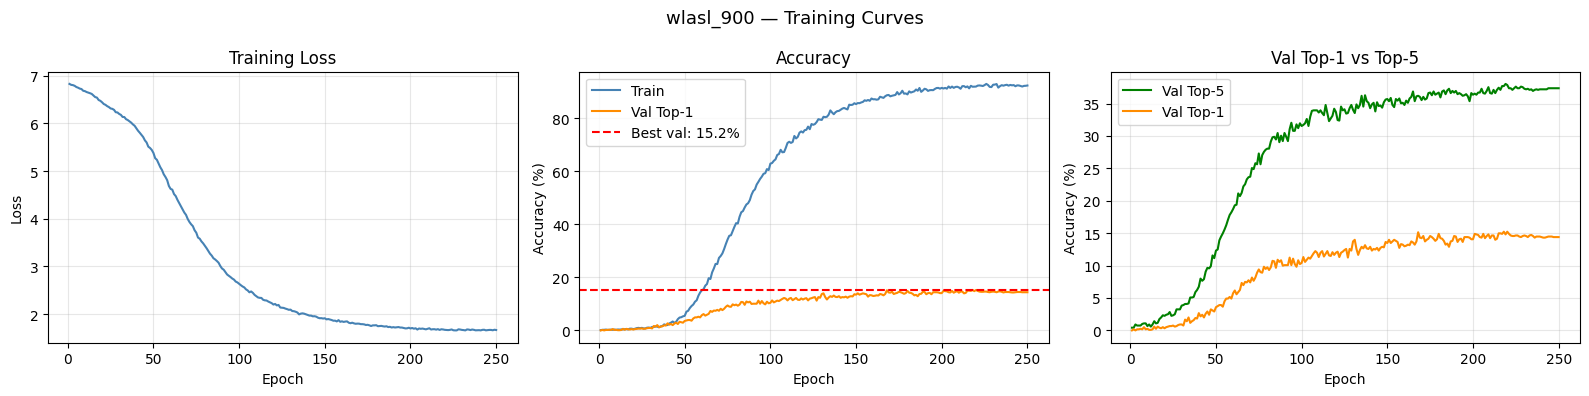

Curves saved to /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/wlasl_900/training_curves.png


In [6]:
# === Training Curves ===

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

epochs_ran = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs_ran, history['train_loss'], color='steelblue')
axes[0].set_title('Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_ran, history['train_acc'], label='Train', color='steelblue')
axes[1].plot(epochs_ran, history['val_top1'],  label='Val Top-1', color='darkorange')
axes[1].axhline(best_val_top1, color='red', linestyle='--',
                label=f'Best val: {best_val_top1:.1f}%')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(epochs_ran, history['val_top5'], color='green', label='Val Top-5')
axes[2].plot(epochs_ran, history['val_top1'], color='darkorange', label='Val Top-1')
axes[2].set_title('Val Top-1 vs Top-5')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.suptitle(f'{EXPERIMENT_NAME} — Training Curves', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Curves saved to {OUTPUT_DIR / "training_curves.png"}')


In [7]:
# === Final Evaluation (val + test) ===

# Load best checkpoint
ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
print(f'Loaded best checkpoint (epoch {ckpt["epoch"] + 1}, '
      f'val_top1={ckpt["val_top1"]:.1f}%)')

# Evaluate
val_metrics,  val_preds,  val_labels  = evaluate(model, val_loader)
test_metrics, test_preds, test_labels = evaluate(model, test_loader)

print()
print('=' * 55)
print(f'RESULTS: {EXPERIMENT_NAME}')
print('=' * 55)
print(f'{"Split":<8} {"Top-1":>8} {"Top-5":>8} {"Samples":>9}')
print('-' * 35)
print(f'{"Val":<8} {val_metrics["top1_acc"]:>7.1f}% {val_metrics["top5_acc"]:>7.1f}% '
      f'{len(val_ds):>9}')
print(f'{"Test":<8} {test_metrics["top1_acc"]:>7.1f}% {test_metrics["top5_acc"]:>7.1f}% '
      f'{len(test_ds):>9}')
print('=' * 55)


Loaded best checkpoint (epoch 218, val_top1=15.2%)

RESULTS: wlasl_900
Split       Top-1    Top-5   Samples
-----------------------------------
Val         15.2%    37.7%      1202
Test        12.5%    33.8%       880


Per-class accuracy on test set (675 classes with test samples):
  Mean:   13.6%
  Median: 0.0%
  Std:    32.7%
  100%:   77
    0%:   568

Top 10 (best accuracy):
  yesterday             100.0%  (n=1)
  yes                   100.0%  (n=1)
  wrong                 100.0%  (n=1)
  work                  100.0%  (n=1)
  white                 100.0%  (n=1)
  where                 100.0%  (n=1)
  wednesday             100.0%  (n=2)
  turkey                100.0%  (n=1)
  to                    100.0%  (n=1)
  time                  100.0%  (n=1)

Bottom 10 (worst accuracy):
  a lot                   0.0%  (n=1)
  accident                0.0%  (n=2)
  action                  0.0%  (n=1)
  adapt                   0.0%  (n=1)
  add                     0.0%  (n=2)
  affect                  0.0%  (n=1)
  africa                  0.0%  (n=1)
  after                   0.0%  (n=2)
  afternoon               0.0%  (n=2)
  age                     0.0%  (n=2)


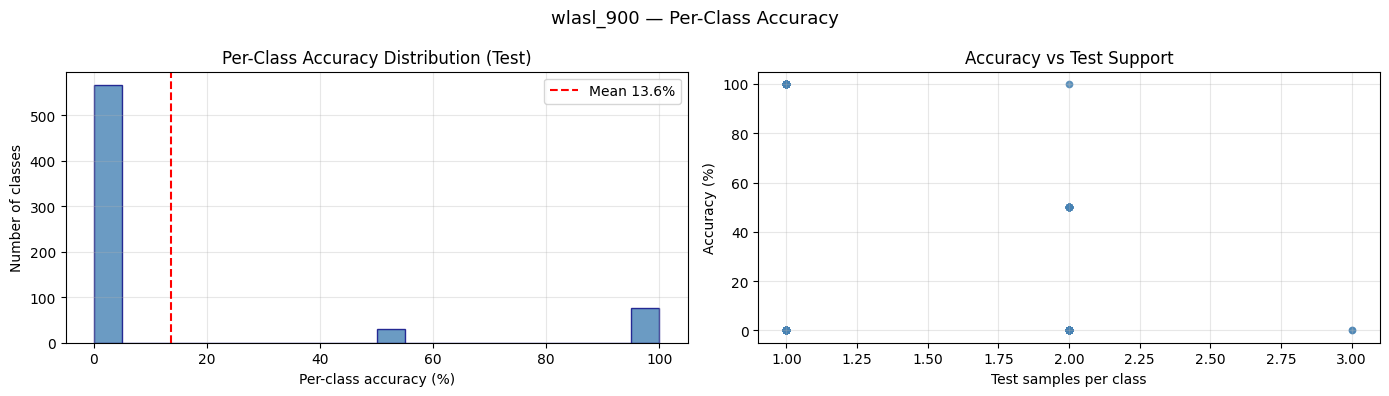

In [8]:
# === Per-Class Accuracy Analysis ===

idx_to_gloss = subset_meta['idx_to_gloss']

# Compute per-class accuracy on test set
per_class_acc = {}
for cls_idx in range(NUM_CLASSES):
    mask = test_labels == cls_idx
    if mask.sum() == 0:
        continue
    acc = 100.0 * (test_preds[mask] == cls_idx).sum() / mask.sum()
    per_class_acc[cls_idx] = {
        'gloss': idx_to_gloss[str(cls_idx)],
        'acc': float(acc),
        'n_test': int(mask.sum()),
    }

# Summary stats
accs = [v['acc'] for v in per_class_acc.values()]
print(f'Per-class accuracy on test set ({len(per_class_acc)} classes with test samples):')
print(f'  Mean:   {np.mean(accs):.1f}%')
print(f'  Median: {np.median(accs):.1f}%')
print(f'  Std:    {np.std(accs):.1f}%')
print(f'  100%:   {sum(1 for a in accs if a == 100)}')
print(f'    0%:   {sum(1 for a in accs if a == 0)}')

# Best and worst classes
sorted_by_acc = sorted(per_class_acc.items(), key=lambda x: x[1]['acc'])
print(f'\nTop 10 (best accuracy):')
for cls_idx, info in sorted_by_acc[-10:][::-1]:
    print(f'  {info["gloss"]:<20} {info["acc"]:>6.1f}%  (n={info["n_test"]})')
print(f'\nBottom 10 (worst accuracy):')
for cls_idx, info in sorted_by_acc[:10]:
    print(f'  {info["gloss"]:<20} {info["acc"]:>6.1f}%  (n={info["n_test"]})')

# Distribution chart (always shown, scales with num_classes)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(accs, bins=20, color='steelblue', edgecolor='navy', alpha=0.8)
axes[0].axvline(np.mean(accs), color='red', linestyle='--',
                label=f'Mean {np.mean(accs):.1f}%')
axes[0].set_xlabel('Per-class accuracy (%)')
axes[0].set_ylabel('Number of classes')
axes[0].set_title('Per-Class Accuracy Distribution (Test)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy vs class support (n_test)
n_tests = [v['n_test'] for v in per_class_acc.values()]
axes[1].scatter(n_tests, accs, alpha=0.4, s=20, color='steelblue')
axes[1].set_xlabel('Test samples per class')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Accuracy vs Test Support')
axes[1].grid(True, alpha=0.3)

plt.suptitle(f'{EXPERIMENT_NAME} — Per-Class Accuracy', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


In [9]:
# === Confusion Matrix (only rendered for <= 100 classes) ===
# For larger subsets, a full confusion matrix is unreadable.
# Instead we show Top-K confusion pairs.

if NUM_CLASSES <= 100:
    import seaborn as sns
    from sklearn.metrics import confusion_matrix

    # Use test set if large enough, otherwise val
    if len(test_labels) >= 50:
        cm_preds, cm_labels = test_preds, test_labels
        cm_title = f'{EXPERIMENT_NAME} — Confusion Matrix (Test)'
    else:
        cm_preds, cm_labels = val_preds, val_labels
        cm_title = f'{EXPERIMENT_NAME} — Confusion Matrix (Val)'

    # Filter to classes present in the labels
    present_classes = sorted(set(cm_labels.tolist()))
    class_names = [idx_to_gloss[str(i)] for i in present_classes]

    cm = confusion_matrix(cm_labels, cm_preds, labels=present_classes)
    fig_size = max(12, len(present_classes) // 3)
    fig, ax = plt.subplots(figsize=(fig_size, fig_size - 2))
    sns.heatmap(cm, xticklabels=class_names, yticklabels=class_names,
                cmap='Blues', fmt='d', annot=len(present_classes) <= 30,
                ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(cm_title)
    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
    plt.show()

else:
    # Top-20 most confused pairs
    print(f'Confusion matrix skipped for {NUM_CLASSES} classes (too large to display).')
    print('Showing Top-20 most confused pairs instead:\n')

    wrong_mask = test_preds != test_labels
    wrong_true = test_labels[wrong_mask]
    wrong_pred = test_preds[wrong_mask]

    pair_counts = Counter(zip(wrong_true.tolist(), wrong_pred.tolist()))
    print(f'{"True":<22} {"Predicted":<22} {"Count":>6}')
    print('-' * 55)
    for (true_idx, pred_idx), count in pair_counts.most_common(20):
        true_name = idx_to_gloss.get(str(true_idx), f'cls_{true_idx}')
        pred_name = idx_to_gloss.get(str(pred_idx), f'cls_{pred_idx}')
        print(f'{true_name:<22} {pred_name:<22} {count:>6}')


Confusion matrix skipped for 900 classes (too large to display).
Showing Top-20 most confused pairs instead:

True                   Predicted               Count
-------------------------------------------------------
explain                describe                    2
investigate            research                    2
lucky                  bad                         2
plan                   prepare                     2
south                  yes                         2
teach                  educate                     2
thank you              sweet                       2
themselves             herself                     2
a lot                  much                        1
accident               wrong                       1
accident               have                        1
action                 french fries                1
adapt                  fast                        1
add                    flexible                    1
add                    microwave       

In [10]:
# === Save Results JSON ===

results = {
    'experiment':     EXPERIMENT_NAME,
    'date':           datetime.now().strftime('%Y-%m-%d %H:%M'),
    'subset_path':    str(SUBSET_PATH),
    'num_classes':    NUM_CLASSES,
    'config':         CONFIG,
    'dataset': {
        'train': len(train_ds),
        'val':   len(val_ds),
        'test':  len(test_ds),
    },
    'training': {
        'best_val_top1':    best_val_top1,
        'best_epoch':       best_epoch,
        'total_epochs':     len(history['train_acc']),
        'training_time_s':  round(elapsed, 1),
    },
    'val_metrics':  val_metrics,
    'test_metrics': test_metrics,
    'per_class_accuracy': {
        str(cls_idx): info
        for cls_idx, info in per_class_acc.items()
    },
    'history': {
        k: [round(float(v), 4) for v in vals]
        for k, vals in history.items()
    },
}

results_path = OUTPUT_DIR / 'results.json'
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

print(f'Results saved to: {results_path}')
print(f'Checkpoint:       {CHECKPOINT_PATH}')
print()
print('Files in output dir:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {p.name}  ({p.stat().st_size // 1024} KB)')


Results saved to: /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/wlasl_900/results.json
Checkpoint:       /home/fransando/Dev/tfg-sign-language-recognition/05_experiments/wlasl_900/best_model.pt

Files in output dir:
  best_model.pt  (9707 KB)
  per_class_accuracy.png  (71 KB)
  results.json  (68 KB)
  training_curves.png  (119 KB)


---
## Summary

| Metric | Val | Test |
|--------|-----|------|
| Top-1 | *(see above)* | *(see above)* |
| Top-5 | *(see above)* | *(see above)* |

### Artifacts
```
05_experiments/wlasl100/
├── best_model.pt          (best checkpoint by Val Top-1)
├── training_curves.png    (loss + accuracy curves)
├── per_class_accuracy.png (distribution + scatter)
├── confusion_matrix.png   (only if num_classes <= 100)
└── results.json           (all metrics + history)
```

### Next step
Compare results from 17a/17b/17c/17d in a summary notebook (18_results_comparison).